# Детекция ArUco маркеров

Используются классы проекта:

- `PhotoArucoDetector` — обработка одиночного фото
- `VideoArucoDetector` — покадровая обработка видео
- `ArucoDetect` — общий детектор: матрица камеры, `solvePnP`, отрисовка

Запускать из корня проекта (`photo-opu`), ядро — `.venv`. Окна OpenCV не используются, результат выводится через matplotlib.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.base import DetectionResult
from src.config import settings
from src.detectors import PhotoArucoDetector, VideoArucoDetector


def show_image(image: np.ndarray, title: str = "Результат") -> None:
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


In [2]:
MARKER_SIZE = 0.2
RUN_NAME = "detection_white_cube_rotation"

PHOTO_PATH = settings.input_photo / "test_photo.png"
PHOTO_OUTPUT_PATH = settings.output_photo / "test_result.jpg"

VIDEO_PATH = settings.input_video / "white_cube_rotation.mov"
VIDEO_OUTPUT_PATH = settings.output_video / RUN_NAME / f"{RUN_NAME}.mp4"


## Генерация ArUco-меток


In [3]:
# from src.utils import generate_aruco_markers

# generated = generate_aruco_markers(count=6, marker_type="4x4")
# print(f"Сгенерировано меток: {len(generated)} в {settings.aruco_markers}")
# for path in generated:
#     print(path.name)


## Фото


Маркеры не найдены.
Маркеры не найдены.
Маркеры не найдены.
Маркеры не найдены.
Найдено маркеров: 1
ID: [5]
Маркер ID=5: tvec=[0.215 0.035 3.28 ], центр в координатах камеры=[1.144 2.885 1.082]
Найдено маркеров: 3
ID: [1, 2, 0]
Маркер ID=1: tvec=[-0.164  0.068  3.256], центр в координатах камеры=[1.125 1.981 2.332]
Маркер ID=2: tvec=[-1.039  0.109  3.359], центр в координатах камеры=[ 2.214 -1.625  2.197]
Маркер ID=0: tvec=[-0.627 -0.648  3.332], центр в координатах камеры=[-1.159 -2.535  2.036]
Маркеры найдены на изображении test_1.png: False


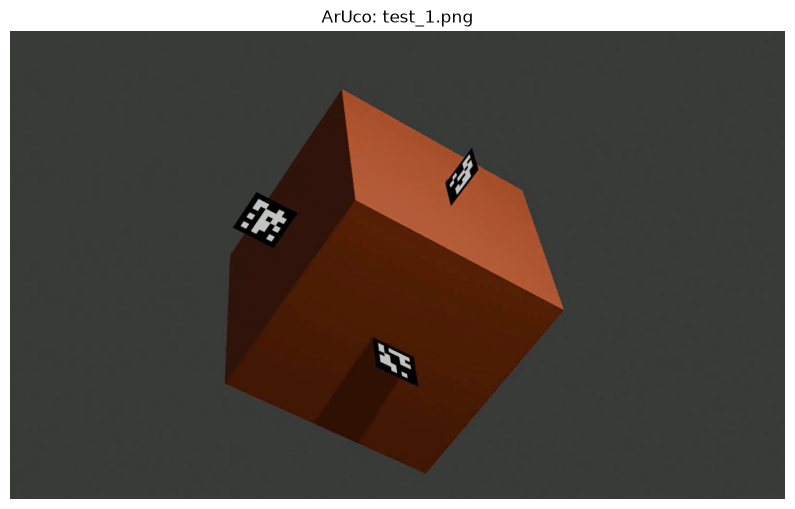

Маркеры найдены на изображении test_2.png: False


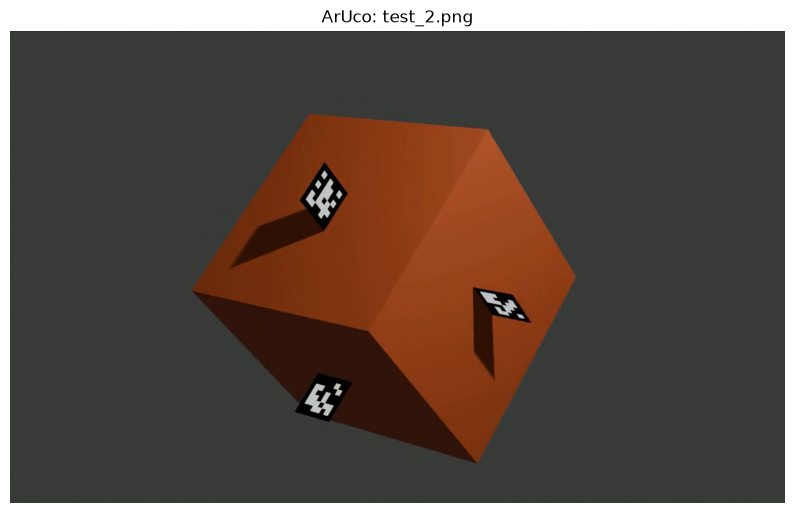

Маркеры найдены на изображении test_3.png: False


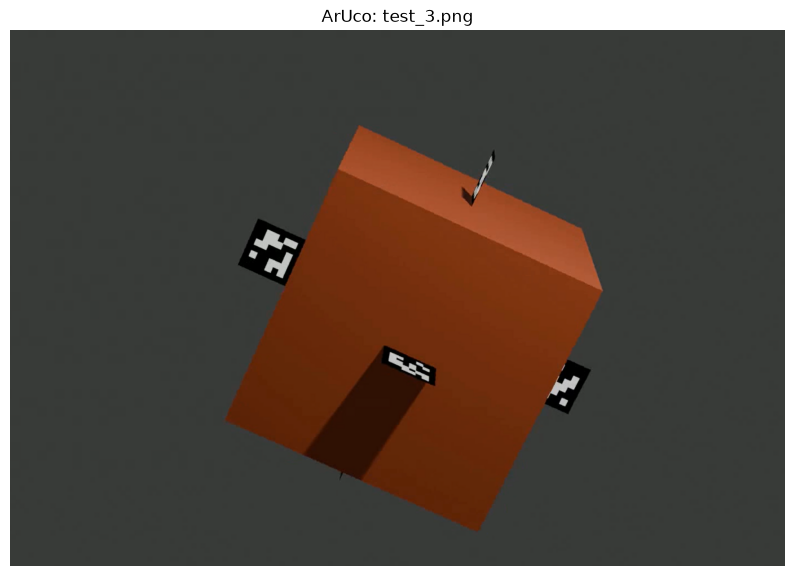

Маркеры найдены на изображении test_4.png: False


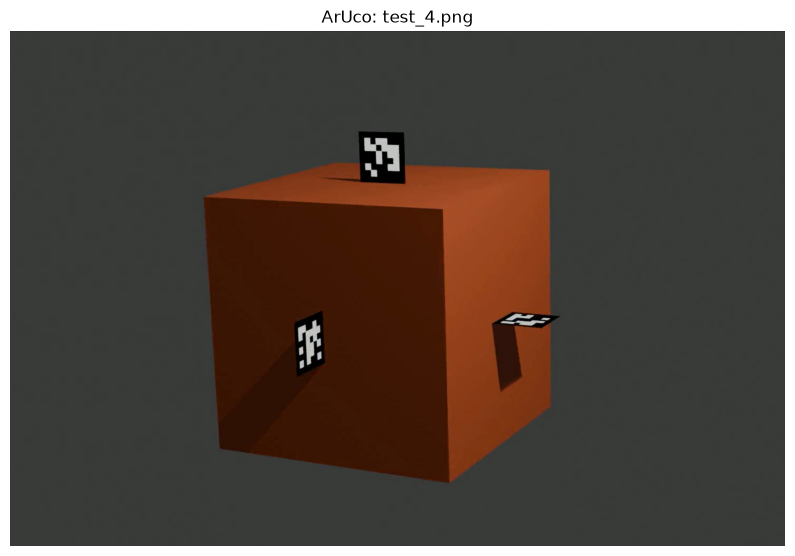

Маркеры найдены на изображении test_5.png: True


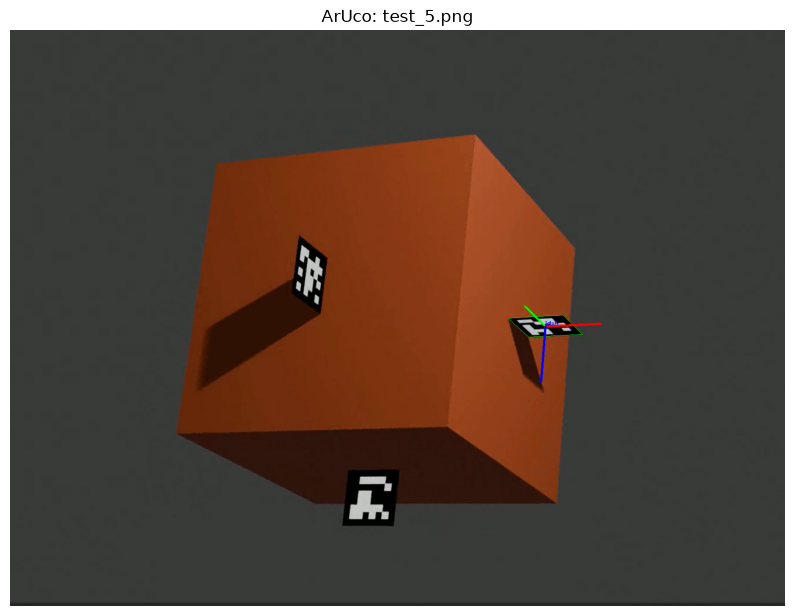

Маркеры найдены на изображении test_photo.png: True


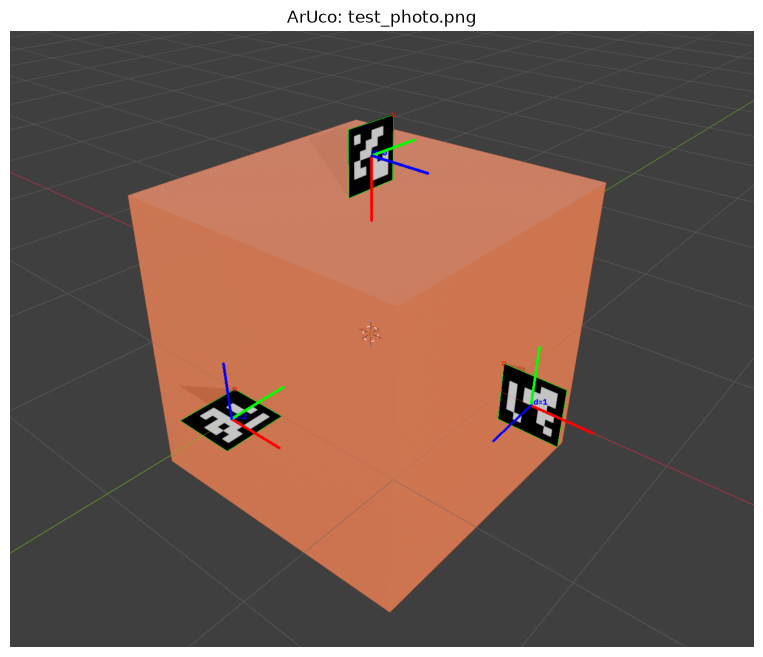

In [4]:
import os

with PhotoArucoDetector(marker_size=MARKER_SIZE) as detector:
    photo_results = {}
    for photo_path in sorted(settings.input_photo.iterdir()):
        output_path = settings.output_photo / photo_path.name
        photo_results[photo_path.name] = detector.process(
            photo_path,
            output_path,
            show=False,
            save=True,
        )

for name, result in photo_results.items():
    print(f"Маркеры найдены на изображении {name}: {result.found}")
    show_image(result.image, f"ArUco: {name}")


## Видео


Кадр 1/501: ID [0, 1, 4]
Кадр 2/501: ID [0, 1, 4]
Кадр 3/501: ID [0, 1, 4]
Кадр 4/501: ID [0, 1, 4]
Кадр 5/501: ID [0, 1, 4]
Кадр 6/501: ID [0, 1, 4]
Кадр 7/501: ID [0, 1, 4]
Кадр 8/501: ID [0, 1, 4]
Кадр 9/501: ID [0, 1, 4]
Кадр 10/501: ID [0, 1, 4]
Кадр 11/501: ID [0, 1, 4]
Кадр 12/501: ID [0, 1, 4]
Кадр 13/501: ID [0, 1, 4]
Кадр 14/501: ID [0, 1, 4]
Кадр 15/501: ID [0, 1, 4]
Кадр 16/501: ID [0, 1, 4]
Кадр 17/501: ID [0, 1, 4]
Кадр 18/501: ID [0, 1, 4]
Кадр 19/501: ID [0, 1, 4]
Кадр 20/501: ID [0, 1, 4]
Кадр 21/501: ID [0, 1, 4]
Кадр 22/501: ID [0, 1, 4]
Кадр 23/501: ID [0, 1, 4]
Кадр 24/501: ID [0, 1, 4]
Кадр 25/501: ID [0, 1, 4]
Кадр 26/501: ID [1, 4]
Кадр 27/501: ID [1, 4]
Кадр 28/501: ID [1, 4]
Кадр 29/501: ID [1, 4]
Кадр 30/501: ID [1, 4]
Кадр 31/501: ID [1, 4]
Кадр 32/501: ID [1, 4]
Кадр 33/501: ID [1]
Кадр 34/501: ID [1, 4]
Кадр 35/501: ID [1, 4]
Кадр 36/501: ID [1, 4]
Кадр 37/501: ID [1, 4]
Кадр 38/501: ID [1, 4]
Кадр 39/501: ID [1, 4]
Кадр 40/501: ID [1, 4]
Кадр 41/501: ID [

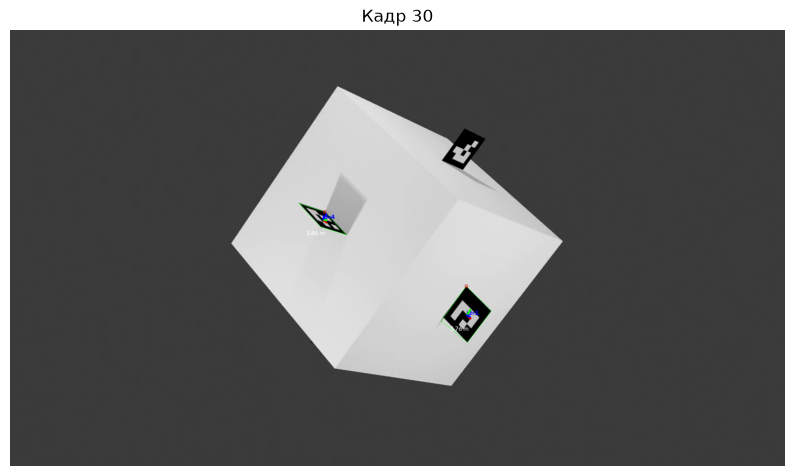

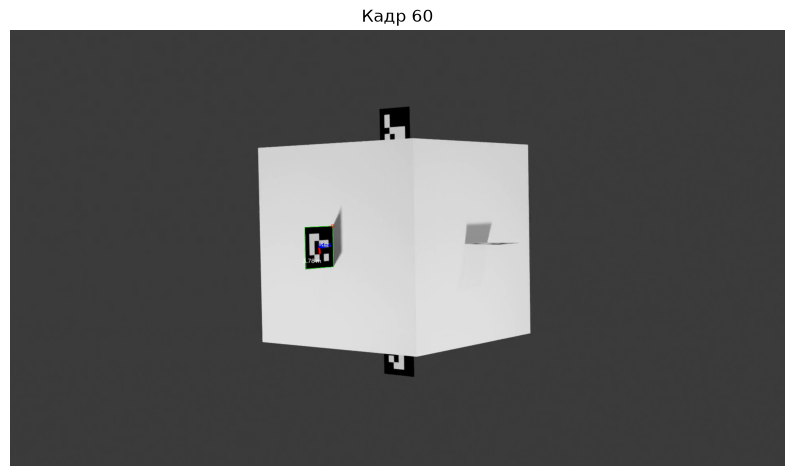

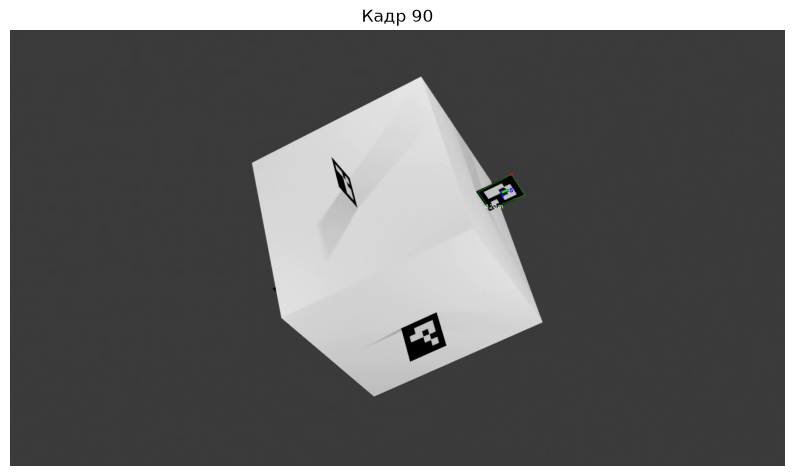

In [5]:
samples: list[DetectionResult] = []

with VideoArucoDetector(marker_size=MARKER_SIZE, dict_id=cv2.aruco.DICT_4X4_50) as detector:
    for frame_result in detector.process(VIDEO_PATH, VIDEO_OUTPUT_PATH, show=False):
        frame_index = frame_result.frame_index or 0
        if frame_result.found and len(samples) < 3 and frame_index % 30 == 0:
            samples.append(frame_result)

stats_path = VIDEO_OUTPUT_PATH.with_suffix(".csv")
print(f"Видео и статистика сохранены в: {VIDEO_OUTPUT_PATH.parent}")
print(pd.read_csv(stats_path, sep=";").to_string(index=False))

for sample in samples:
    show_image(sample.image, f"Кадр {sample.frame_index}")
